# Mini-Project 01 — Customers Like You

**PCA or Truncated SVD for Online Retail II.** This notebook runs the documented source scripts in order, shows the measured outputs, and summarizes the data engineer (DE) and machine learning (ML) tasks.

**Privacy:** never print, plot, or include real customer IDs in deliverables. `data/processed/customer_index.csv` is an internal map only.

**Reproducibility:** fixed random seed (42); use both workbook sheets; filter products using training data only; hold out the last two months **before fitting** any model.


## 1. Setup and method decision (J1, ML1)

The proposed method is **Truncated SVD**: the customer × product matrix is sparse and SVD fits without centering each product column. PCA is a measured comparison at the same rank, not a substitute for evaluating both methods.

We use binary purchase indicators, require at least 10 training customers per product, and pre-select **k = 50** as a modest storage/compute compromise. See `METHOD_DECISION.md` for details and limitations.

**Success criteria:** shrink storage, report runtime, compare recommendation hit@10 to best sellers on unseen purchases, and describe customer segments without IDs.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
print('Project folder:', ROOT)


Project folder: e:\LA\Customers_Like_You


## 2. DE1–DE6: read, clean, split, and build the sparse matrix

The single script below loads both annual sheets, profiles every column, logs cleaning rows removed, splits by a date cutoff, holds out **new products for known customers** in the final two months, and writes a sparse binary training-only matrix. Product filtering and index maps are created from training data only.


In [2]:
%run build_matrix.py


Loading both workbook sheets...
Sheets: [('Year 2009-2010', 525461), ('Year 2010-2011', 541910)]
1 cancel invoices: removed 19,494; remaining 1,047,877
2 non-positive quantity: removed 3,457; remaining 1,044,420
3 non-positive price: removed 2,750; remaining 1,041,670
4 non-product codes: removed 6,049; remaining 1,035,621
5 missing customer ID: removed 234,062; remaining 801,559
6 invalid invoice date: removed 0; remaining 801,559
Date cut: 2011-10-09 12:50:00 train rows: 683060 test rows: 118499
Matrix: (5473, 3684) nnz 413459 sparsity % 97.95
Holdout: 44714 unseen customer-product pairs across 1913 customers


In [3]:
display(pd.read_csv('results/data_profile.csv').head(20))
display(pd.read_csv('results/cleaning_log.csv'))
with open('results/matrix_report.json', encoding='utf-8') as f:
    matrix_report = json.load(f)
for key in ['raw_rows', 'cleaned_rows', 'time_cutoff_exclusive_train',
            'matrix_shape', 'matrix_nonzeros', 'matrix_sparsity_percent',
            'dense_float64_MB', 'csr_float32_MB',
            'test_eligible_customers', 'test_heldout_unique_customer_product_pairs']:
    print(f'{key}: {matrix_report[key]}')


,sheet,column,dtype,row_count,missing_count,missing_pct
0,Year 2009-2010,Invoice,object,525461,0,0.000000
1,Year 2009-2010,StockCode,object,525461,0,0.000000
2,Year 2009-2010,Description,object,525461,2928,0.557225
3,Year 2009-2010,Quantity,int64,525461,0,0.000000
4,Year 2009-2010,InvoiceDate,datetime64[ns],525461,0,0.000000
5,Year 2009-2010,Price,float64,525461,0,0.000000
6,Year 2009-2010,Customer ID,float64,525461,107927,20.539488
7,Year 2009-2010,Country,object,525461,0,0.000000
8,Year 2010-2011,Invoice,object,541910,0,0.000000
9,Year 2010-2011,StockCode,object,541910,0,0.000000


,step,rows_before,rows_removed,rows_remaining,reason
0,1 cancel invoices,1067371,19494,1047877,"C-prefixed invoice represents a cancellation, ..."
1,2 non-positive quantity,1047877,3457,1044420,Negative/zero quantities are returns or adjust...
2,3 non-positive price,1044420,2750,1041670,Zero/negative prices cannot represent paid pur...
3,4 non-product codes,1041670,6049,1035621,Keep 5-6 digit stock numbers with optional var...
4,5 missing customer ID,1035621,234062,801559,Unidentified purchases cannot be linked to a c...
5,6 invalid invoice date,801559,0,801559,A valid time is required for a leak-free chron...


raw_rows: 1067371
cleaned_rows: 801559
time_cutoff_exclusive_train: 2011-10-09 12:50:00
matrix_shape: [5473, 3684]
matrix_nonzeros: 413459
matrix_sparsity_percent: 97.94936965258132
dense_float64_MB: 161.300256
csr_float32_MB: 3.329568
test_eligible_customers: 1913
test_heldout_unique_customer_product_pairs: 44714


## 3. ML2–ML7: fit k options, recommend, evaluate, compare PCA, and segment

`analyze.py` fits Truncated SVD at **k = 10, 20, 50, 100, 200** and reports the relative reconstruction error. It generates cosine-similarity product neighbours and customer recommendations; the test targets were held out prior to fitting. Both SVD and PCA are scored with the **same** recommendation formula; best sellers are derived solely from the training set.

ML6 clusters standardized first-two SVD components into four groups and describes them using training-period products and countries. ML7 optionally compares binary vs winsorized counts vs log counts.


In [4]:
%run analyze.py


Training matrix (5473, 3684) held-out customers 1913
Fitting SVD for k: [10, 20, 50, 100, 200]
   {'method': 'Truncated SVD', 'k': 10, 'fit_seconds': 0.020128399999975954, 'observed_peak_RSS_MB': 442.916864, 'relative_reconstruction_error': 0.898014898426421, 'variance_explained_fraction': 0.1540120542049408}
   {'method': 'Truncated SVD', 'k': 20, 'fit_seconds': 0.0305647999998655, 'observed_peak_RSS_MB': 444.960768, 'relative_reconstruction_error': 0.875888359312861, 'variance_explained_fraction': 0.1950511336326599}
   {'method': 'Truncated SVD', 'k': 50, 'fit_seconds': 0.05687880000004952, 'observed_peak_RSS_MB': 448.843776, 'relative_reconstruction_error': 0.8323402295758747, 'variance_explained_fraction': 0.2730311155319214}
   {'method': 'Truncated SVD', 'k': 100, 'fit_seconds': 0.1340885999998136, 'observed_peak_RSS_MB': 454.262784, 'relative_reconstruction_error': 0.7812885473089514, 'variance_explained_fraction': 0.3594609797000885}
   {'method': 'Truncated SVD', 'k': 200, 'f

## 4. Measured method comparison and baseline (ML2, ML4, ML5)

Review the full table; do not change claims in the report to make a model appear stronger than it is. Hit@10 is the proportion of eligible **customers** with at least one future new product in their top 10. Timings and memory vary across computers.


In [5]:
display(pd.read_csv('results/svd_k_curve.csv'))
display(pd.read_csv('results/method_comparison.csv'))
with open('results/model_metrics.json', encoding='utf-8') as f:
    metrics = json.load(f)
print('Baseline hit@10:', f"{metrics['baseline_hit_rate_at_10']:.2%}")
print('SVD hit@10:', f"{metrics['svd_hit_rate_at_10']:.2%}")
print('PCA hit@10:', f"{metrics['pca_hit_rate_at_10']:.2%}")


,method,k,fit_seconds,observed_peak_RSS_MB,relative_reconstruction_error,variance_explained_fraction
0,Truncated SVD,10,0.020128,442.916864,0.898015,0.154012
1,Truncated SVD,20,0.030565,444.960768,0.875888,0.195051
2,Truncated SVD,50,0.056879,448.843776,0.832340,0.273031
3,Truncated SVD,100,0.134089,454.262784,0.781289,0.359461
4,Truncated SVD,200,0.267196,479.059968,0.702743,0.481766


,method,k,fit_seconds,observed_peak_RSS_MB,stored_factors_MB_float32,variance_explained_fraction,relative_reconstruction_error,hit_rate_at_10,hit_customers,baseline_hit_rate_at_10,score_eligible_customers_seconds,component_1_meaning
0,Truncated SVD,50,0.056879,448.843776,1.831400,0.273031,0.832340,0.240460,460,0.268688,0.021992,Raw buying activity / popularity (uncentred)
1,PCA,50,0.085260,467.886080,1.846136,0.274148,0.831646,0.240983,461,0.268688,0.023571,Variation relative to average purchase profile...


Baseline hit@10: 26.87%
SVD hit@10: 24.05%
PCA hit@10: 24.10%


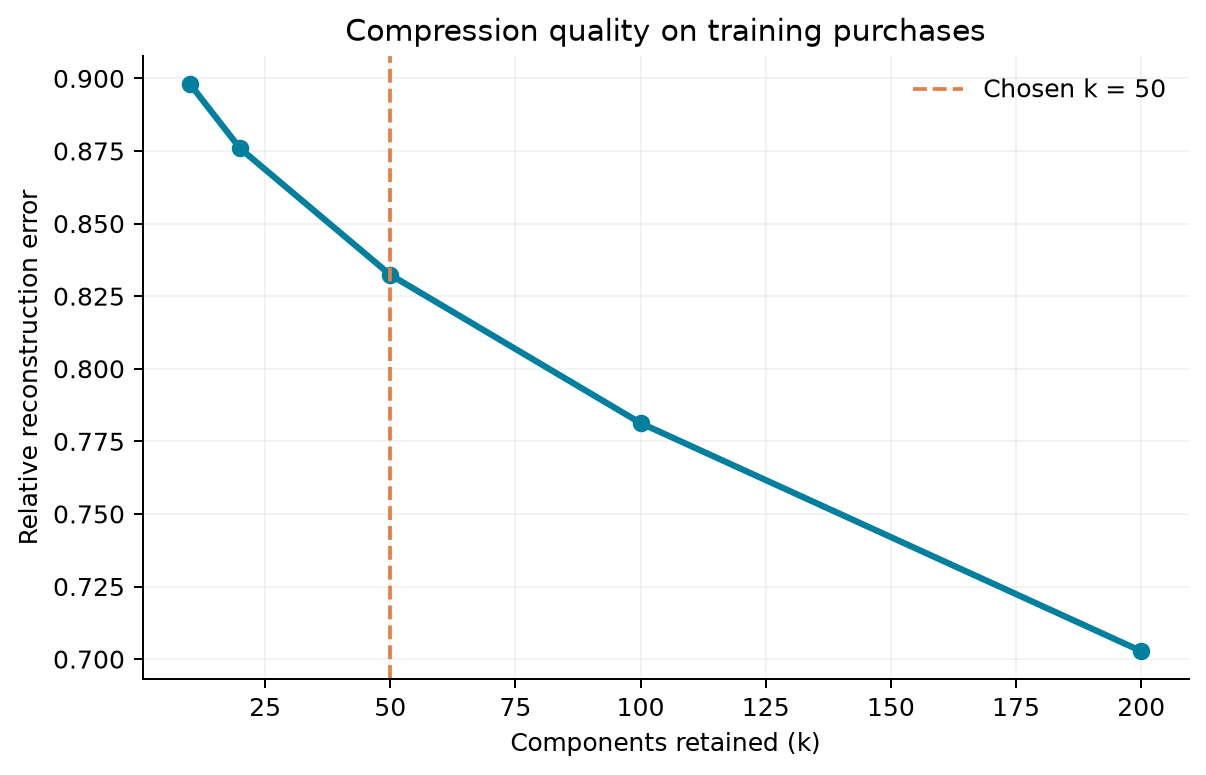

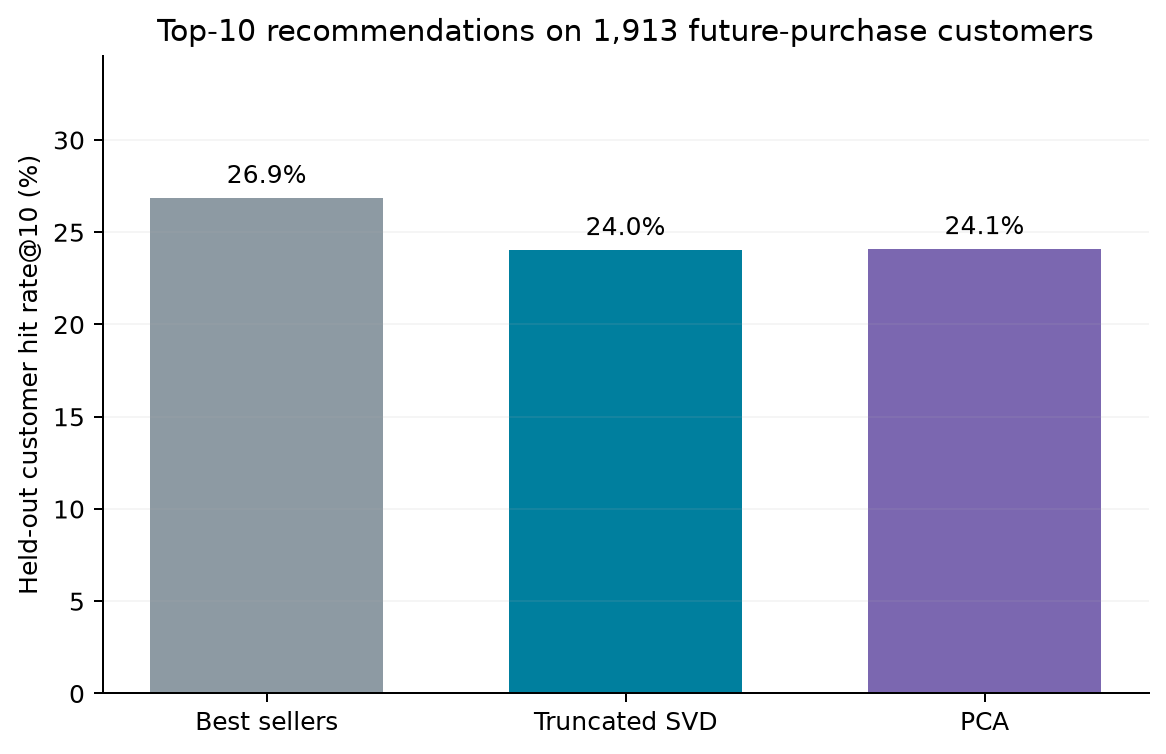

In [6]:
display(Image(filename='figures/svd_error_curve.png'))
display(Image(filename='figures/hit_rates.png'))


## 5. Marketing segments (ML6)

The figure shows customer groups in a two-component map. Segment labels are based on the breadth of their purchase histories and the dominant product patterns observed **in training**. No actual customer identifiers are included.


,group,customers,share_percent,distinctive_products,most_bought_products,top_countries,median_distinct_products,segment_name
0,1,4026,73.561118,WHITE HANGING HEART T-LIGHT HOLDER | JUMBO BAG...,WHITE HANGING HEART T-LIGHT HOLDER | REGENCY C...,"United Kingdom (92%), Germany (1%), France (1%)",27.0,Occasional mixed-gift shoppers
1,2,510,9.318473,LUNCH BAG SPACEBOY DESIGN | PLASTERS IN TIN SP...,PACK OF 72 RETROSPOT CAKE CASES | LUNCH BAG SP...,"United Kingdom (77%), Germany (7%), France (5%)",166.0,Lunch-bag and partyware shoppers
2,3,145,2.649370,WHITE HANGING HEART T-LIGHT HOLDER | 60 TEATIM...,WHITE HANGING HEART T-LIGHT HOLDER | REGENCY C...,"United Kingdom (97%), EIRE (2%), Germany (1%)",391.0,Broad-catalog gift shoppers
3,4,792,14.471040,WHITE HANGING HEART T-LIGHT HOLDER | HEART OF ...,WHITE HANGING HEART T-LIGHT HOLDER | HEART OF ...,"United Kingdom (97%), Cyprus (1%), France (0%)",121.0,Home decor regulars


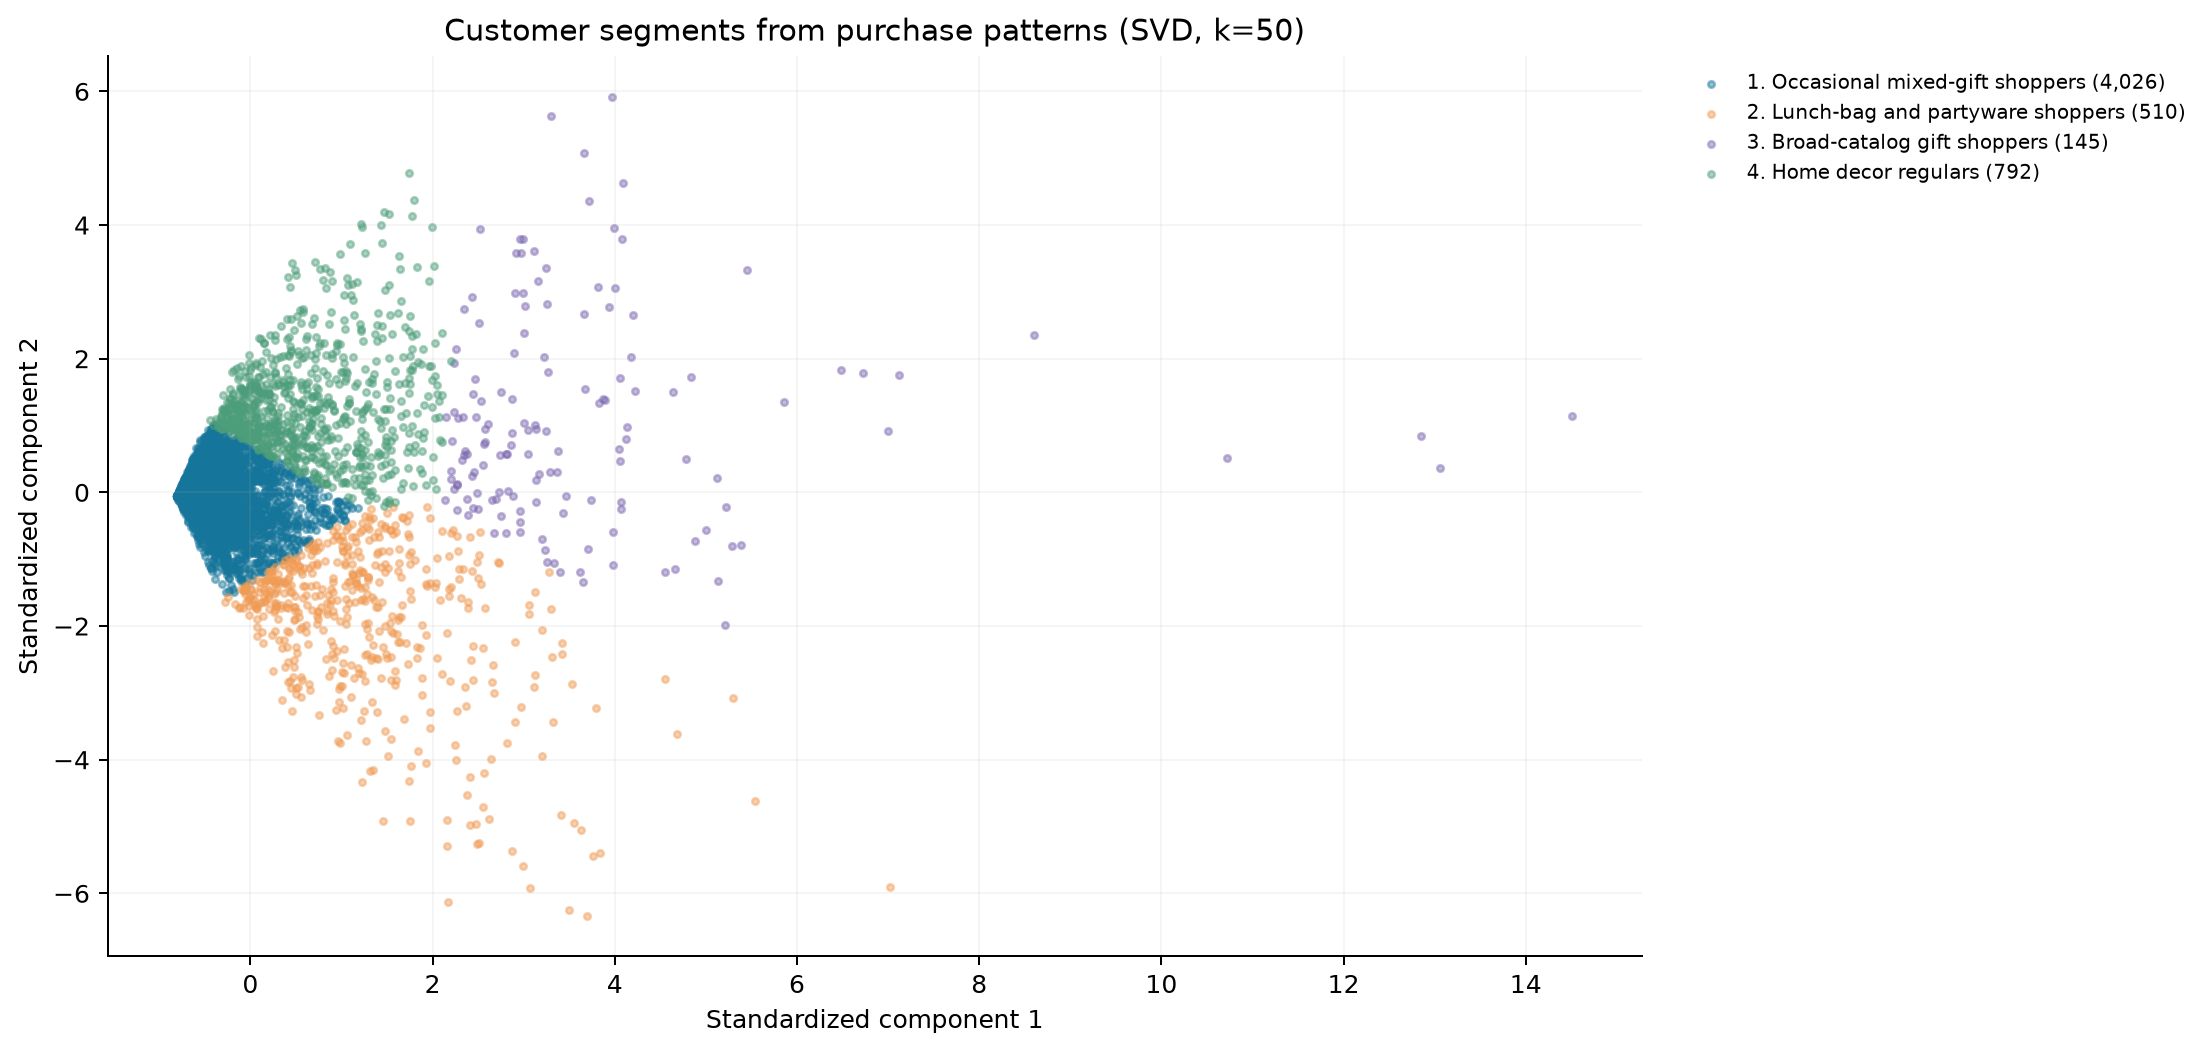

In [7]:
display(pd.read_csv('results/segments.csv'))
display(Image(filename='figures/customer_map.png'))


## 6. Examples and sensitivity (ML3, ML7)

Product suggestions use cosine similarity in factor space. The sensitivity table holds the training/test memberships fixed while changing the matrix's purchase values.


In [8]:
display(pd.read_csv('results/recommendation_examples.csv'))
display(pd.read_csv('results/sensitivity.csv'))


,source_product,suggested_products,top_similarity
0,WHITE HANGING HEART T-LIGHT HOLDER,RED HANGING HEART T-LIGHT HOLDER | CANDLEHOLDE...,0.911463
1,REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER | GREEN REGENC...,0.683936
2,PACK OF 72 RETROSPOT CAKE CASES,PACK OF 60 PINK PAISLEY CAKE CASES | 60 TEATIM...,0.816497
3,BAKING SET 9 PIECE RETROSPOT,BAKING SET SPACEBOY DESIGN | RETROSPOT TEA SET...,0.883598
4,ASSORTED COLOUR BIRD ORNAMENT,PAINTED METAL PEARS ASSORTED | PACK OF 6 BIRDY...,0.916112


,purchase_value,hit_rate_at_10,chosen_k
0,binary,0.240460,50
1,count_winsor99,0.162572,50
2,log1p_quantity,0.215369,50
